In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

**SLpM** - Significant Strikes Landed per Minute

**Str. Acc.** - Significant Striking Accuracy

**SApM** - Significant Strikes Absorbed per Minute

**Str. Def.** - Significant Strike Defence (the % of opponents strikes that did not land)

**TD Avg.** - Average Takedowns Landed per 15 minutes

**TD Acc.** - Takedown Accuracy

**TD Def.** - Takedown Defense (the % of opponents TD attempts that did not land)

**Sub. Avg.** - Average Submissions Attempted per 15 minutes

In [ ]:
fighter_df = pd.read_csv("fighter.csv")
fighter_df.describe()

,weight_lbs,reach_inches,slpm,str_acc,sapm,str_def,td_avg,td_acc,td_def,sub_avg
count,4493.000000,2589.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000
mean,169.777654,71.508691,2.479932,35.702685,3.218422,42.402750,1.246285,25.702467,39.929273,0.566710
std,39.462430,4.280318,1.986239,20.280797,2.961669,22.183612,1.939417,27.969000,34.390822,1.428137
min,105.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,145.000000,69.000000,0.850000,27.000000,1.620000,35.000000,0.000000,0.000000,0.000000,0.000000
50%,155.000000,72.000000,2.400000,41.000000,2.980000,50.000000,0.580000,22.000000,45.000000,0.000000
75%,185.000000,75.000000,3.680000,49.000000,4.300000,57.000000,1.910000,44.000000,66.000000,0.700000
max,770.000000,84.000000,17.650000,100.000000,52.500000,100.000000,32.140000,100.000000,100.000000,21.900000


Peleadores con estadísticas: 3827 de 4581


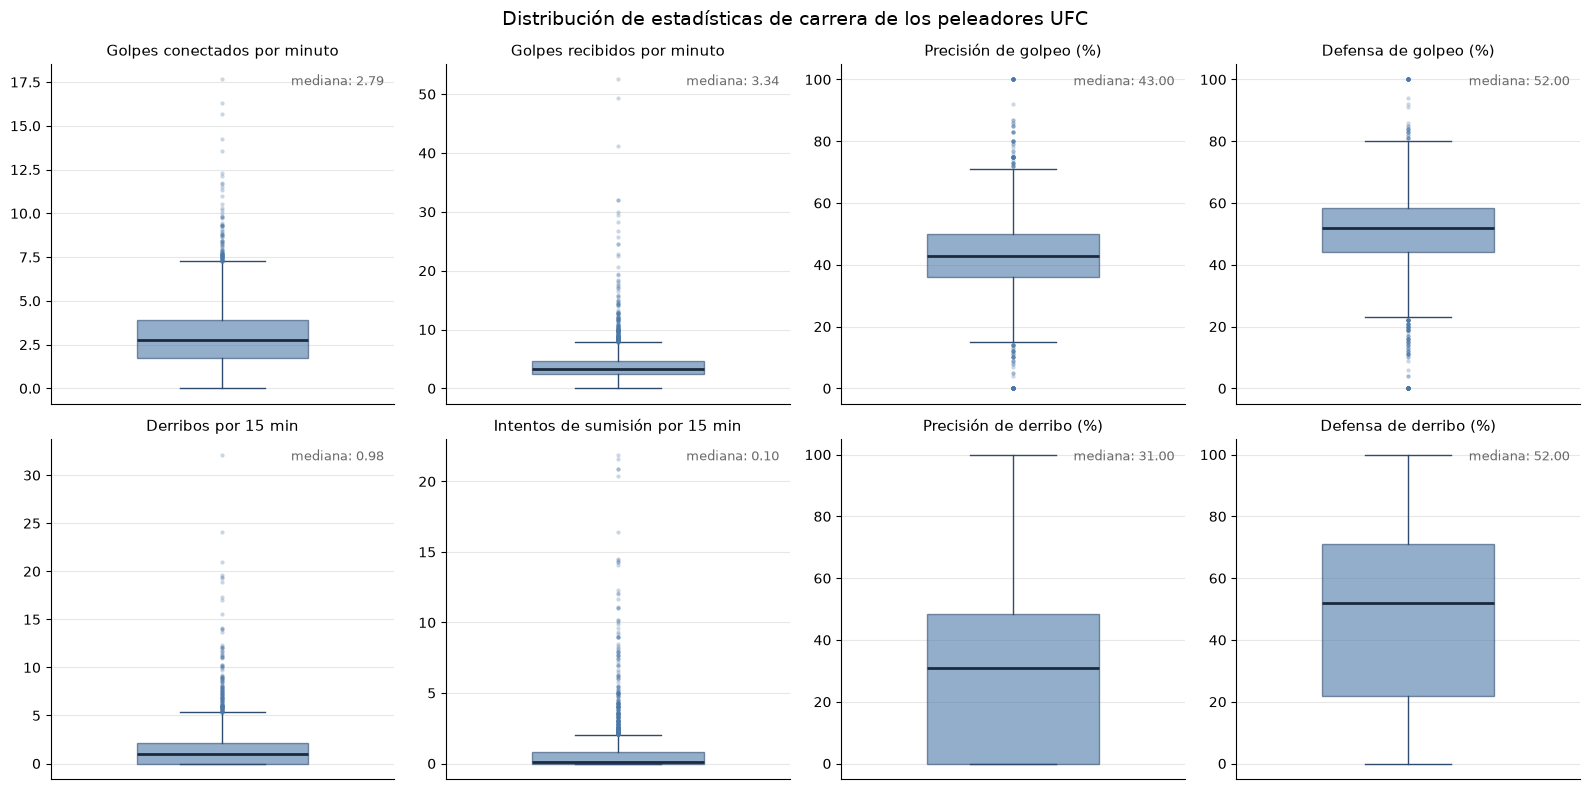

In [ ]:
estadisticas = {
    "slpm": "Golpes conectados por minuto",
    "sapm": "Golpes recibidos por minuto",
    "str_acc": "Precisión de golpeo (%)",
    "str_def": "Defensa de golpeo (%)",
    "td_avg": "Derribos por 15 min",
    "sub_avg": "Intentos de sumisión por 15 min",
    "td_acc": "Precisión de derribo (%)",
    "td_def": "Defensa de derribo (%)",
}
cols = list(estadisticas)

# Peleadores sin estadísticas registradas tienen todo en 0: se excluyen
stats_df = fighter_df.loc[~(fighter_df[cols] == 0).all(axis=1), cols]
print(f"Peleadores con estadísticas: {len(stats_df)} de {len(fighter_df)}")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (col, titulo) in zip(axes.flat, estadisticas.items()):
    datos = stats_df[col].dropna()
    ax.boxplot(
        datos,
        widths=0.5,
        patch_artist=True,
        boxprops=dict(facecolor="#4C78A8", alpha=0.6, edgecolor="#2F4B6E"),
        medianprops=dict(color="#1B2A3D", linewidth=2),
        whiskerprops=dict(color="#2F4B6E"),
        capprops=dict(color="#2F4B6E"),
        flierprops=dict(
            marker="o",
            markersize=3,
            markerfacecolor="#4C78A8",
            markeredgecolor="none",
            alpha=0.3,
        ),
    )
    ax.set_title(titulo, fontsize=11)
    ax.set_xticks([])
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.text(
        0.97,
        0.97,
        f"mediana: {datos.median():.2f}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        color="dimgray",
    )

fig.suptitle(
    "Distribución de estadísticas de carrera de los peleadores UFC", fontsize=14
)
fig.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Regresiones lineales simples con sklearn: str_acc ~ x, una por cada predictor
y_col = "str_acc"
predictores = ["str_def", "td_acc", "td_def", "slpm"]

y = stats_df[y_col].to_numpy(float)
n = len(y)
resultados = []

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
for ax, x_col in zip(axes.flat, predictores):
    X = stats_df[[x_col]].to_numpy(float)  # sklearn espera una matriz 2D
    modelo = LinearRegression().fit(X, y)
    y_pred = modelo.predict(X)
    pendiente, intercepto = modelo.coef_[0], modelo.intercept_
    r2 = r2_score(y, y_pred)

    # sklearn no da errores estándar: se calculan a partir de los residuos
    residuos = y - y_pred
    x = X[:, 0]
    se = np.sqrt(residuos @ residuos / (n - 2) / ((x - x.mean()) ** 2).sum())

    resultados.append(
        {
            "predictor": x_col,
            "intercepto": intercepto,
            "pendiente": pendiente,
            "error_std": se,
            "t": pendiente / se,
            "R2": r2,
            "RMSE": np.sqrt(mean_squared_error(y, y_pred)),
            "n": n,
        }
    )

    ax.scatter(x, y, s=6, alpha=0.2, color="#4C78A8", edgecolors="none")
    xs = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
    ax.plot(xs, modelo.predict(xs), color="#1B2A3D", linewidth=2)
    ax.set_title(
        f"{estadisticas[x_col]}\ny = {intercepto:.2f} + {pendiente:.4f}x   R² = {r2:.3f}",
        fontsize=11,
    )
    ax.set_xlabel(estadisticas[x_col])
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel(estadisticas[y_col])
fig.suptitle("Regresión lineal simple de la precisión de golpeo (sklearn)", fontsize=14)
fig.tight_layout()
plt.show()

pd.DataFrame(resultados).set_index("predictor").round(4)